# 08 — AutoMFLES | PharmaDemand

**Objetivo:** avaliar AutoMFLES como quarto candidato para o ensemble (`LightGBM + XGBoost + SARIMAX + [AutoMFLES]`, com Ridge como metamodelo).

A interface da classe segue seu `LightGBMRegressorAnomaly`: `gridSearchFind()`, `fit_with_best_params()`, `predict()`, `evaluate()`, `save_model()`, `save_best_params()` e `save_metrics()`.

**Diferença importante:** AutoMFLES, nesta implementação, utiliza **a série diária real** (univariada). Não se deve entregar o Parquet inteiro com duplicações D+7/D+15 diretamente ao treino. O `date` do Parquet já é **data-alvo**; `forecast_origin = date - horizon_days`.

Este notebook inclui GridSearch temporal só no treino, backtest **exatamente D+7 e D+15**, MAE/RMSE/R²/WAPE/Bias, gráficos e artefatos para o stacking. Os números de teste não são utilizados no ajuste de hiperparâmetros.

## 0. Preparação do ambiente

No `.venv` do projeto: `pip install statsforecast scikit-learn pandas numpy pyarrow matplotlib joblib nbformat`.

Copie **`AutoMFLESForecaster.py` para `src/models/AutoMFLESForecaster.py`**. Se preferir explorar com o notebook e a classe na mesma pasta, o import alternativo também funciona.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Encontrar a raiz do projeto a partir do VSCode/Jupyter
HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src").is_dir()), HERE)
for p in [ROOT, HERE]:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

try:
    from src.models.AutoMFLESForecaster import AutoMFLESForecaster, calculate_metrics
except ImportError:
    from AutoMFLESForecaster import AutoMFLESForecaster, calculate_metrics

print("Raiz identificada:", ROOT)

d:\PROJETOS\git_repo\PharmaDemand-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raiz identificada: D:\PROJETOS\git_repo\PharmaDemand-ml


## 1. Configuração

Altere `CATEGORY` para outro ATC. O arquivo Parquet fornece apenas as **datas e splits** necessários; sempre que disponível, o CSV `salesdaily.csv` fornece os **valores reais não interpolados**.

- `EVAL_STEP = 7`: amostra uma data-alvo a cada 7 dias, em **ambos** os horizontes; diagnóstico mais rápido.
- `EVAL_STEP = 1`: todas as datas-alvo no teste; recomendado para comparação definitiva, **mais caro** porque AutoMFLES reajusta o modelo para cada origem.

In [2]:
CATEGORY = "N02BE"
TARGET = "quantity"
DATE = "date"
HORIZONS = (7, 15)
EVAL_STEP = 7                  # mudar para 1 na avaliacao definitiva
N_SPLITS = 3
MODEL_DIR = ROOT / "models" / "baseline" / "automfles"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_CANDIDATES = [
    ROOT / "data" / "features" / "anomaly_predictions.parquet",
    ROOT / "data" / "anomaly_predictions.parquet",
    HERE / "anomaly_predictions.parquet",
    HERE / "anomaly_predictions(5).parquet",
]
CSV_CANDIDATES = [
    ROOT / "data" / "raw" / "salesdaily.csv",
    ROOT / "data" / "salesdaily.csv",
    HERE / "salesdaily.csv",
    HERE / "salesdaily(2).csv",
]

PARQUET_PATH = next((p for p in PARQUET_CANDIDATES if p.exists()), None)
RAW_CSV_PATH = next((p for p in CSV_CANDIDATES if p.exists()), None)
if PARQUET_PATH is None:
    raise FileNotFoundError("Configure PARQUET_PATH em 1. Configuracao.")
print("Parquet:", PARQUET_PATH)
print("Vendas originais:", RAW_CSV_PATH or "nao localizado; sera usado o Parquet com auditoria")

Parquet: D:\PROJETOS\git_repo\PharmaDemand-ml\data\features\anomaly_predictions.parquet
Vendas originais: D:\PROJETOS\git_repo\PharmaDemand-ml\data\raw\salesdaily.csv


## 2. Leitura e auditoria da estrutura

**Não somar D+7 ou D+15 ao campo `date`.** Esse deslocamento já é representado por `forecast_origin` na engenharia de atributos. Checar a integridade desse alinhamento antes de treinar.

In [3]:
features = pd.read_parquet(PARQUET_PATH)
required = {"date", "category", "horizon_days", "split", "quantity"}
missing_columns = required - set(features.columns)
if missing_columns:
    raise ValueError(f"Parquet sem colunas obrigatorias: {missing_columns}")

meta = features.loc[
    features["category"].astype(str).eq(CATEGORY)
    & features["horizon_days"].isin(HORIZONS)
    & features["split"].isin(["train", "test"]),
    ["date", "category", "horizon_days", "split", "quantity"]
    + (["forecast_origin"] if "forecast_origin" in features.columns else [])
].copy()
meta["date"] = pd.to_datetime(meta["date"]).dt.normalize()
meta["quantity"] = pd.to_numeric(meta["quantity"], errors="raise")

if meta.empty:
    raise ValueError(f"Nao ha dados para {CATEGORY} em D+7/D+15.")
if meta.duplicated(["date", "horizon_days"]).any():
    raise ValueError("Parquet tem duplicacao por (date, horizon_days) para esta categoria.")

if "forecast_origin" in meta:
    origin = pd.to_datetime(meta["forecast_origin"]).dt.normalize()
    expected_origin = meta["date"] - pd.to_timedelta(meta["horizon_days"], unit="D")
    if not origin.eq(expected_origin).all():
        raise ValueError("forecast_origin inconsistente: date ja deveria ser a data-alvo.")

split_count = meta.groupby("date")["split"].nunique()
if (split_count > 1).any():
    raise ValueError("A mesma data tem split divergente entre D+7/D+15.")

meta_split = meta[["date", "split"]].drop_duplicates()
last_train = meta_split.loc[meta_split["split"].eq("train"), "date"].max()
first_test = meta_split.loc[meta_split["split"].eq("test"), "date"].min()
last_test = meta_split.loc[meta_split["split"].eq("test"), "date"].max()

if pd.isna(last_train) or pd.isna(first_test):
    raise ValueError("Nao encontrei split train/test para a categoria escolhida.")
if not first_test > last_train:
    raise ValueError("Sobreposicao temporal entre train e test.")
print("Categoria:", CATEGORY)
print("Treino ate:", last_train.date(), " | Teste:", first_test.date(), "ate", last_test.date())
print("Linhas do painel (D+7/D+15):", len(meta))
display(meta.head())

Categoria: N02BE
Treino ate: 2019-04-08  | Teste: 2019-04-09 ate 2019-10-08
Linhas do painel (D+7/D+15): 4078


,date,category,horizon_days,split,quantity,forecast_origin
0,2014-03-06,N02BE,7,train,44.1,2014-02-27
1,2014-03-07,N02BE,7,train,25.0,2014-02-28
2,2014-03-08,N02BE,7,train,27.6,2014-03-01
3,2014-03-09,N02BE,7,train,11.3,2014-03-02
4,2014-03-10,N02BE,7,train,47.0,2014-03-03


## 3. Construir UMA série diária (sem duplicação de horizonte)

A fonte preferida é o CSV original, sem interpolar `quantity <= 0`. Um zero real continua sendo zero.

Se o CSV não estiver disponível, o notebook confere se D+7 e D+15 do Parquet apresentam exatamente o mesmo valor por `date`. Se houver divergência, ele **interrompe** e pede a fonte diária, evitando treinar com alvos desalinhados.

In [4]:
if RAW_CSV_PATH is not None:
    raw = pd.read_csv(RAW_CSV_PATH, usecols=["datum", CATEGORY])
    raw[DATE] = pd.to_datetime(raw["datum"], format="%m/%d/%Y", errors="raise").dt.normalize()
    daily = raw[[DATE, CATEGORY]].rename(columns={CATEGORY: TARGET}).copy()
    print("Fonte de venda real: CSV original (sem interpolacao)")
else:
    # Data-alvo igual entre ambos os horizontes, se o Parquet estiver integro.
    spread = meta.groupby(DATE)[TARGET].agg(["min", "max"])
    mismatch = ~np.isclose(spread["min"], spread["max"], rtol=0, atol=1e-8, equal_nan=True)
    if mismatch.any():
        raise ValueError(
            f"{int(mismatch.sum())} datas apresentam quantity divergente entre D+7 e D+15. "
            "Use o CSV original para recuperar a venda real sem interpolacao."
        )
    daily = meta.loc[meta["horizon_days"].eq(HORIZONS[0]), [DATE, TARGET]].copy()
    additional_dates = meta.loc[
        ~meta[DATE].isin(daily[DATE]), [DATE, TARGET]
    ].drop_duplicates(subset=DATE)
    daily = pd.concat([daily, additional_dates], ignore_index=True)
    warnings.warn("CSV original nao encontrado: o alvo foi recuperado do Parquet, "
                  "que pode ter sofrido transformacoes anteriores.")

# Auditar a correspondencia entre CSV e Parquet, quando ambos existem.
if RAW_CSV_PATH is not None:
    comparison = meta.merge(daily, on=DATE, how="left", suffixes=("_parquet", "_original"), validate="many_to_one")
    comparable = comparison["quantity_original"].notna() & comparison["quantity_parquet"].notna()
    different = comparable & ~np.isclose(
        comparison["quantity_parquet"].fillna(0), comparison["quantity_original"].fillna(0),
        rtol=0, atol=1e-6
    )
    print("Divergencias entre valores do Parquet e CSV:", int(different.sum()))
    if different.any():
        display(comparison.loc[different, [DATE, "horizon_days", "quantity_parquet", "quantity_original"]].head())
        warnings.warn("Diferencas encontradas: treinamento usara sempre os valores reais do CSV.")

daily[DATE] = pd.to_datetime(daily[DATE]).dt.normalize()
daily[TARGET] = pd.to_numeric(daily[TARGET], errors="raise")
daily = daily.sort_values(DATE).reset_index(drop=True)
if daily.duplicated(DATE).any():
    raise ValueError("CSV/serie tem data duplicada. Corrija a fonte antes de prosseguir.")
if not np.isfinite(daily[TARGET].to_numpy(dtype=float)).all():
    raise ValueError("Existem valores NaN/inf no historico. Investigue a fonte; nao interpole o alvo.")

train_daily = daily.loc[daily[DATE] <= last_train, [DATE, TARGET]].copy()
test_daily = daily.loc[daily[DATE].between(first_test, last_test), [DATE, TARGET]].copy()

for name, part in [("Treino", train_daily), ("Teste", test_daily)]:
    expected = pd.date_range(part[DATE].min(), part[DATE].max(), freq="D")
    if len(part) != len(expected):
        missing_days = expected.difference(part[DATE])
        raise ValueError(f"{name}: faltam {len(missing_days)} datas: {missing_days[:5].tolist()}")
if test_daily[DATE].min() != train_daily[DATE].max() + pd.Timedelta(days=1):
    raise ValueError("Lacuna entre fim do treino e inicio do teste: conferir a serie real.")

print("Treino:", train_daily.shape, " | Teste:", test_daily.shape)
print("Zeros verdadeiros no treino:", int(train_daily[TARGET].eq(0).sum()))
display(train_daily.tail(3), test_daily.head(3))

Fonte de venda real: CSV original (sem interpolacao)
Divergencias entre valores do Parquet e CSV: 0
Treino: (1923, 2)  | Teste: (183, 2)
Zeros verdadeiros no treino: 24


C:\Users\AlexK\AppData\Local\Temp\ipykernel_24188\2223251191.py:52: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  if test_daily[DATE].min() != train_daily[DATE].max() + pd.Timedelta(days=1):


,date,quantity
1920,2019-04-06,13.2
1921,2019-04-07,19.0
1922,2019-04-08,10.0


,date,quantity
1923,2019-04-09,12.0
1924,2019-04-10,34.0
1925,2019-04-11,15.9


## 4. Instanciar o AutoMFLES + GridSearch temporal

- `n_splits=3`: três validações em janelas futuras ordenadas.
- Cada fold prevê os próximos 15 dias **D+1..D+15**; o GridSearch externo seleciona pelos RMSEs desses blocos.
- O AutoMFLES também executa otimização *interna* (`n_windows=2`, `metric='mse'`). Por isso, o grid externo é deliberadamente pequeno.
- **As features do LightGBM e do Isolation Forest não entram** nesta versão univariada.

In [5]:
model = AutoMFLESForecaster(
    target_col=TARGET,
    numeric_features=None,
    categorical_features=None,
    model_dir=str(MODEL_DIR),
    date_col=DATE,
    series_col=None,             # uma categoria ATC por dataframe
    forecast_horizon=15,
    min_train_days=90,
    n_splits=N_SPLITS,
    random_state=3,
    scoring="neg_root_mean_squared_error",
)

param_grid = {
    "model__season_length": [(7,), (7, 30)],
    "model__n_windows": [2],
    "model__metric": ["mse"],
}

grid_result = model.gridSearchFind(train_daily, param_grid=param_grid)
print("Melhores parametros:", model.best_params)
print("RMSE CV (D+1..D+15):", -float(grid_result.best_score_))

display(pd.DataFrame(grid_result.cv_results_)[[
    "params", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score"))

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Melhores parametros: {'model__metric': 'mse', 'model__n_windows': 2, 'model__season_length': (7,)}
RMSE CV (D+1..D+15): 11.894093857490248


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__metric': 'mse', 'model__n_windows': 2...",-11.894094,1.376903,1
1,"{'model__metric': 'mse', 'model__n_windows': 2...",-11.965807,0.980478,2


## 5. Salvar configurações e modelo ajustado

O `GridSearchCV(refit=True)` já ajusta automaticamente o melhor modelo em todo o treino. Para reutilizar no próximo notebook sem novo GridSearch, use `fit_with_best_params(train_daily, params_path=...)`.

In [6]:
params_path = model.save_best_params()
model_path = model.save_model()
print("Parametros:", params_path)
print("Modelo:", model_path)

# Exemplo em outra execucao:
# new_model = AutoMFLESForecaster(target_col=TARGET, model_dir=MODEL_DIR,
#                                 date_col=DATE, forecast_horizon=15)
# new_model.fit_with_best_params(train_daily, params_path=str(params_path))
# new_model.predict(pd.DataFrame({DATE: pd.date_range(last_train + pd.Timedelta(days=1), periods=15)}))

Parametros: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\automfles\automfles_best_params.json
Modelo: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\automfles\automfles_model.joblib


## 6. Backtest EXATAMENTE D+7 e D+15

Diferente do `evaluate_backtest()` em blocos D+1..D+15, este método avalia uma única data-alvo por horizonte. Em D+7, a previsão para `T` usa apenas vendas até `T-7`; em D+15, até `T-15`. Os dois são comparados contra a **mesma venda real na data T**.

**Custo:** `EVAL_STEP = 7` é exploratório; para métricas finais e previsões alinhadas diariamente ao stacking, mude para **`EVAL_STEP = 1`**. Esse ajuste requer muitos re-treinamentos e pode ser demorado.

In [7]:
predictions = model.backtest_fixed_horizons(
    df_train=train_daily,
    df_test=test_daily,
    horizons=HORIZONS,
    step_size=EVAL_STEP,
    verbose=True,
)
predictions["category"] = CATEGORY

# Uma observacao por (categoria, data-alvo, horizonte)
assert not predictions.duplicated(["category", DATE, "horizon_days"]).any()
assert (predictions[DATE] - predictions["forecast_origin"]).dt.days.eq(predictions["horizon_days"]).all()
print("Previsoes geradas:", len(predictions))
display(predictions.head(10))

Ajustes do backtest: 1/54 (origem 2019-03-25)
Ajustes do backtest: 10/54 (origem 2019-04-29)
Ajustes do backtest: 20/54 (origem 2019-06-03)
Ajustes do backtest: 30/54 (origem 2019-07-08)
Ajustes do backtest: 40/54 (origem 2019-08-12)
Ajustes do backtest: 50/54 (origem 2019-09-16)
Ajustes do backtest: 54/54 (origem 2019-10-01)
Previsoes geradas: 54


,date,quantity,forecast_origin,horizon_days,y_pred,model,category
0,2019-04-09,12.0,2019-04-02,7,22.250018,AutoMFLES,N02BE
1,2019-04-09,12.0,2019-03-25,15,25.720736,AutoMFLES,N02BE
2,2019-04-16,27.2,2019-04-09,7,20.087500,AutoMFLES,N02BE
3,2019-04-16,27.2,2019-04-01,15,26.534856,AutoMFLES,N02BE
4,2019-04-23,18.4,2019-04-16,7,18.937500,AutoMFLES,N02BE
5,2019-04-23,18.4,2019-04-08,15,12.986078,AutoMFLES,N02BE
6,2019-04-30,22.0,2019-04-23,7,28.200000,AutoMFLES,N02BE
7,2019-04-30,22.0,2019-04-15,15,12.111164,AutoMFLES,N02BE
8,2019-05-07,33.4,2019-04-30,7,24.800000,AutoMFLES,N02BE
9,2019-05-07,33.4,2019-04-22,15,35.492429,AutoMFLES,N02BE


## 7. Métricas MAE, RMSE, R², WAPE e Bias por horizonte

Atenção: um R² calculado com poucos pontos (quando `EVAL_STEP = 7`) pode ser muito instável. Compare com seus resultados do AutoTheta/LightGBM/SARIMAX somente após alinhar **as mesmas datas e os mesmos horizontes**.

In [8]:
metrics = model.metrics_by_horizon(predictions)
metrics.insert(0, "category", CATEGORY)
metrics.insert(1, "model", "AutoMFLES")
metrics["evaluation_step"] = EVAL_STEP
print("AutoMFLES — backtest D+7 / D+15")
display(metrics.round(4))

for row in metrics.itertuples():
    print(f"D+{row.horizon_days}: n={row.n_obs}, MAE={row.mae:.4f}, "
          f"RMSE={row.rmse:.4f}, R²={row.r2:.4f}, "
          f"WAPE={row.wape_pct:.2f}%, Bias={row.bias:.4f}")

summary_dict = {
    str(row.horizon_days): {
        "mae": row.mae, "rmse": row.rmse, "r2": row.r2,
        "wape_pct": row.wape_pct, "bias": row.bias, "n_obs": row.n_obs,
        "evaluation_step": EVAL_STEP,
    } for row in metrics.itertuples()
}
print("Metricas salvas:", model.save_metrics(
    summary_dict, filename=f"automfles_metrics_{CATEGORY}_step{EVAL_STEP}.json"
))

AutoMFLES — backtest D+7 / D+15


,category,model,horizon_days,mae,rmse,r2,wape_pct,bias,n_obs,evaluation_step
0,N02BE,AutoMFLES,7,7.1868,10.3460,0.2452,31.7934,-0.1497,27,7
1,N02BE,AutoMFLES,15,7.8321,10.9145,0.1599,34.6481,-0.8347,27,7


D+7: n=27, MAE=7.1868, RMSE=10.3460, R²=0.2452, WAPE=31.79%, Bias=-0.1497
D+15: n=27, MAE=7.8321, RMSE=10.9145, R²=0.1599, WAPE=34.65%, Bias=-0.8347
Metricas salvas: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\automfles\automfles_metrics_N02BE_step7.json


## 8. Gráficos: vendas reais x previsões e erros

O gráfico mostra apenas as datas efetivamente amostradas; não une dados de diferentes horizontes no mesmo eixo sem identificação.

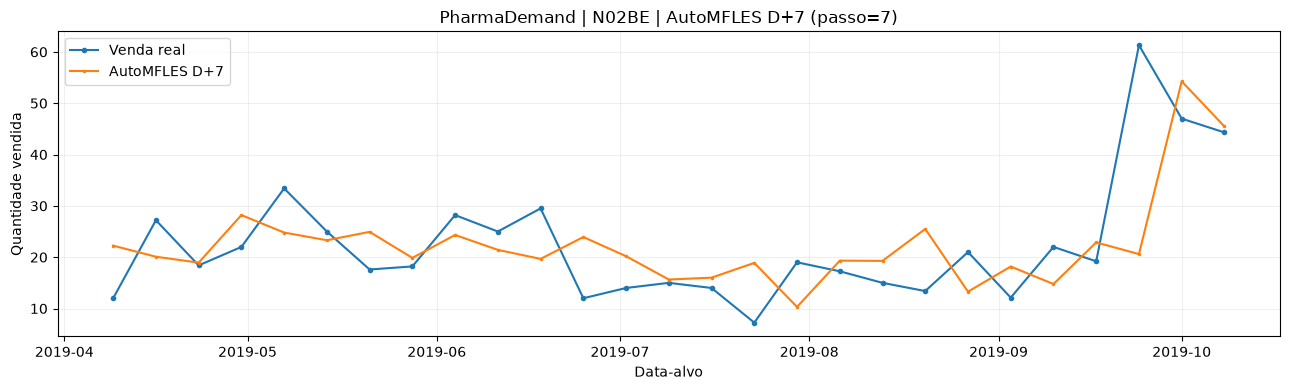

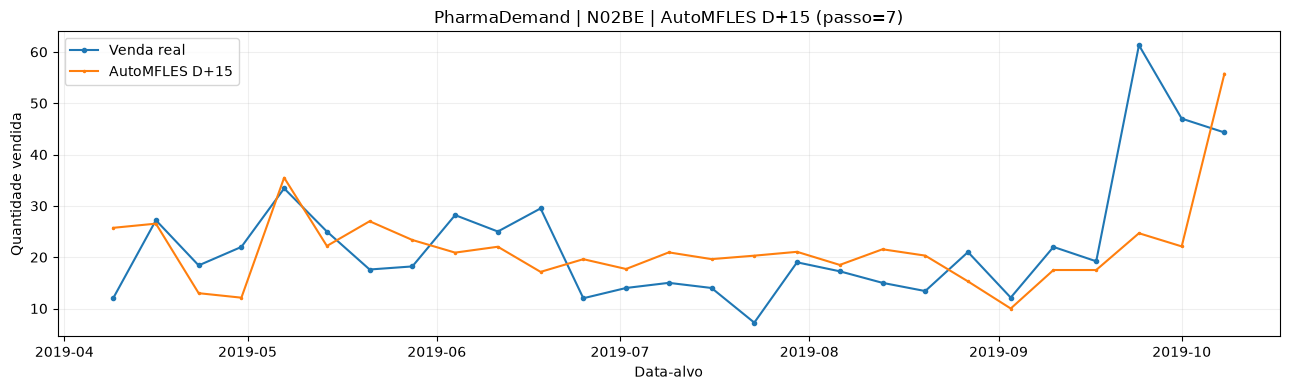

In [9]:
for horizon in HORIZONS:
    subset = predictions.loc[predictions["horizon_days"].eq(horizon)].sort_values(DATE)
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(subset[DATE], subset[TARGET], label="Venda real", marker="o", markersize=3)
    ax.plot(subset[DATE], subset["y_pred"], label=f"AutoMFLES D+{horizon}", marker=".", markersize=3)
    ax.set_title(f"PharmaDemand | {CATEGORY} | AutoMFLES D+{horizon} (passo={EVAL_STEP})")
    ax.set_xlabel("Data-alvo")
    ax.set_ylabel("Quantidade vendida")
    ax.legend()
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

## 9. Diagnóstico dos maiores erros

In [10]:
diagnostic = predictions.copy()
diagnostic["error"] = diagnostic["y_pred"] - diagnostic[TARGET]
diagnostic["abs_error"] = diagnostic["error"].abs()
for h in HORIZONS:
    print(f"\nMaiores erros em D+{h}:")
    display(diagnostic.loc[diagnostic["horizon_days"].eq(h)]
            .nlargest(10, "abs_error")[[
                DATE, "forecast_origin", "category", "horizon_days",
                TARGET, "y_pred", "error", "abs_error"
            ]])


Maiores erros em D+7:


,date,forecast_origin,category,horizon_days,quantity,y_pred,error,abs_error
48,2019-09-24,2019-09-17,N02BE,7,61.30,20.600000,-40.700000,40.700000
38,2019-08-20,2019-08-13,N02BE,7,13.40,25.500000,12.100000,12.100000
22,2019-06-25,2019-06-18,N02BE,7,12.00,23.927213,11.927213,11.927213
30,2019-07-23,2019-07-16,N02BE,7,7.25,18.889192,11.639192,11.639192
0,2019-04-09,2019-04-02,N02BE,7,12.00,22.250018,10.250018,10.250018
20,2019-06-18,2019-06-11,N02BE,7,29.50,19.663289,-9.836711,9.836711
32,2019-07-30,2019-07-23,N02BE,7,19.00,10.305158,-8.694842,8.694842
8,2019-05-07,2019-04-30,N02BE,7,33.40,24.800000,-8.600000,8.600000
40,2019-08-27,2019-08-20,N02BE,7,21.00,13.280134,-7.719866,7.719866
12,2019-05-21,2019-05-14,N02BE,7,17.60,24.932632,7.332632,7.332632



Maiores erros em D+15:


,date,forecast_origin,category,horizon_days,quantity,y_pred,error,abs_error
49,2019-09-24,2019-09-09,N02BE,15,61.30,24.666790,-36.633210,36.633210
51,2019-10-01,2019-09-16,N02BE,15,47.00,22.100000,-24.900000,24.900000
1,2019-04-09,2019-03-25,N02BE,15,12.00,25.720736,13.720736,13.720736
31,2019-07-23,2019-07-08,N02BE,15,7.25,20.295718,13.045718,13.045718
21,2019-06-18,2019-06-03,N02BE,15,29.50,17.136536,-12.363464,12.363464
53,2019-10-08,2019-09-23,N02BE,15,44.30,55.750000,11.450000,11.450000
7,2019-04-30,2019-04-15,N02BE,15,22.00,12.111164,-9.888836,9.888836
13,2019-05-21,2019-05-06,N02BE,15,17.60,27.000000,9.400000,9.400000
23,2019-06-25,2019-06-10,N02BE,15,12.00,19.610602,7.610602,7.610602
17,2019-06-04,2019-05-20,N02BE,15,28.20,20.889457,-7.310543,7.310543


## 10. Exportar previsões para comparação / stacking

A tabela contém `category`, `date` (data-alvo), `forecast_origin`, `horizon_days`, `quantity`, `y_pred`, `model`. Ela pode ser combinada **somente pelas chaves corretas** com previsões de outros modelos.

**Atenção ao stacking:** estas previsões no holdout servem para **avaliação**. Não treine o Ridge usando `quantity` do holdout; gere previsões out-of-fold dentro do treino para ajustar o metamodelo, depois avalie no holdout.

In [ ]:
OUTPUT_DIR = ROOT / "data" / "predictions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / f"automfles_{CATEGORY}_fixed_horizons_step{EVAL_STEP}.parquet"
export_cols = ["category", DATE, "forecast_origin", "horizon_days", TARGET, "y_pred", "model"]
predictions[export_cols].to_parquet(output_path, index=False)
print("Previsoes exportadas:", output_path)
print("Concluido: modelo AutoMFLES, parametros, metricas e previsoes foram gerados.")

## 11. Checklist para comparação honesta

1. Usar `EVAL_STEP=1` na avaliação definitiva, se o custo computacional for viável.
2. Fazer os modelos concorrentes preverem as **mesmas** datas-alvo e horizontes D+7/D+15.
3. Não atribuir melhora do ensemble só pelo R² de um componente isolado; verificar ablação e correlação de erros.
4. Nunca treinar o Ridge no teste: montar previsões OOF em treino/validação temporal.
5. Verificar a fonte das vendas reais e não interpolar o alvo com valores posteriores.

**Fonte da interface AutoMFLES:** documentação oficial Nixtla/StatsForecast: https://nixtlaverse.nixtla.io/statsforecast/src/core/models.html#automfles